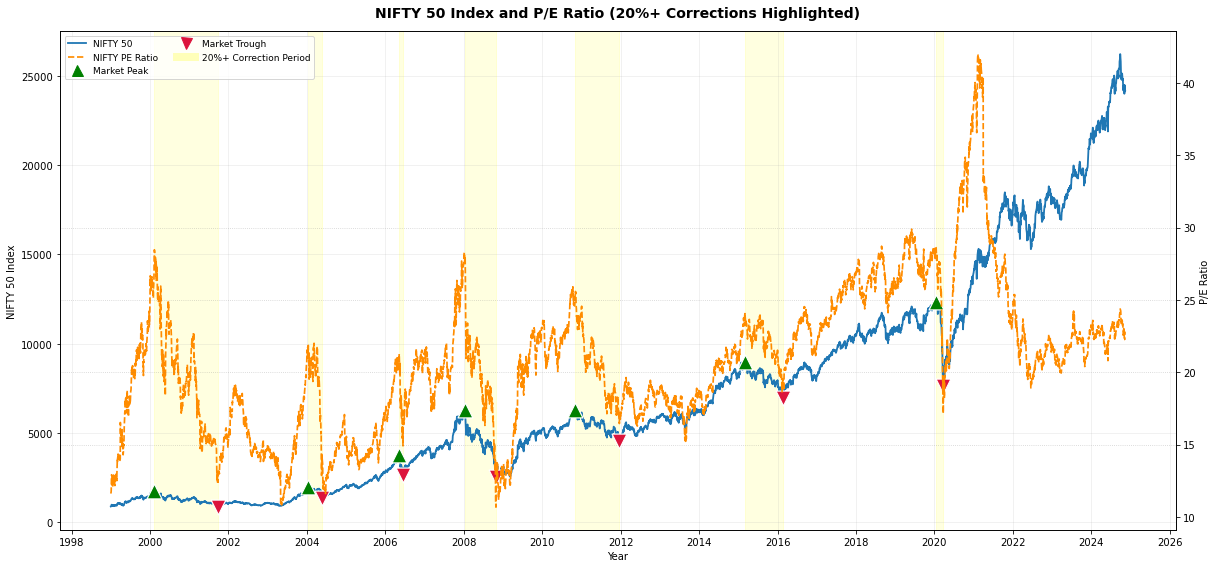

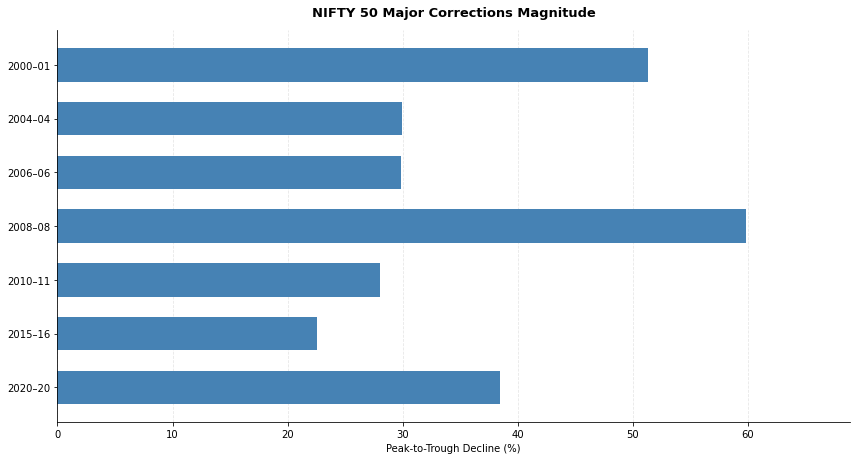

Found 7 correction(s) of 20% or more.
All outputs saved in: C:\Users\hmksasikumar\Downloads\NIFTY_Outputs


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# =====================================================
# 1. LOAD DATA & SETUP OUTPUT DIRECTORY
# =====================================================
file_path = ""
out_dir = Path()
out_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(file_path)
df["Date"] = pd.to_datetime(df["Date"])

for col in ["Close", "EPS", "P/E", "P/B", "Div Yield %"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Date", "Close", "EPS", "P/E"])
      .sort_values("Date")
      .drop_duplicates(subset="Date", keep="last")
      .reset_index(drop=True)
)

# =====================================================
# 2. DETECT 20%+ CORRECTION EPISODES
# =====================================================
episodes = []
peak_i = trough_i = 0
peak = trough = float(df.loc[0, "Close"])

def check_and_add_episode(p_i, t_i, p_val, t_val):
    fall = (t_val / p_val - 1) * 100
    if fall <= -20:
        episodes.append({
            "Peak Date": df.loc[p_i, "Date"], "Peak NIFTY": p_val,
            "Peak PE": float(df.loc[p_i, "P/E"]),
            "Trough Date": df.loc[t_i, "Date"], "Trough NIFTY": t_val,
            "Trough PE": float(df.loc[t_i, "P/E"]), "Fall %": fall
        })

for i in range(1, len(df)):
    val = float(df.loc[i, "Close"])
    if val >= peak:
        check_and_add_episode(peak_i, trough_i, peak, trough)
        peak_i = trough_i = i
        peak = trough = val
    elif val < trough:
        trough, trough_i = val, i

check_and_add_episode(peak_i, trough_i, peak, trough)

# =====================================================
# 3. CHART 1 — DUAL-AXIS TIME SERIES CHART 
# =====================================================
fig, ax = plt.subplots(figsize=(17, 8))
ax2 = ax.twinx()

for e in episodes:
    ax.axvspan(e["Peak Date"], e["Trough Date"], alpha=0.12, color="yellow")
    ax.scatter(e["Peak Date"], e["Peak NIFTY"], marker="^", s=220, zorder=7, color="green", edgecolors="white", linewidths=1.2)
    ax.scatter(e["Trough Date"], e["Trough NIFTY"], marker="v", s=220, zorder=7, color="crimson", edgecolors="white", linewidths=1.2)
    # Text annotations removed for a cleaner look

line1, = ax.plot(df["Date"], df["Close"], linewidth=1.8, label="NIFTY 50")
line2, = ax2.plot(df["Date"], df["P/E"], color="darkorange", linestyle="--", linewidth=1.7, label="NIFTY PE Ratio")

for level in [15, 20, 25, 30]:
    ax2.axhline(level, linestyle=":", linewidth=0.8, alpha=0.4, color="grey")

ax.set_title("NIFTY 50 Index and P/E Ratio (20%+ Corrections Highlighted)", fontsize=14, pad=14, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("NIFTY 50 Index")
ax2.set_ylabel("P/E Ratio")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.22)

legend_handles = [
    line1, line2,
    plt.Line2D([], [], marker="^", linestyle="None", color="green", markersize=11, label="Market Peak"),
    plt.Line2D([], [], marker="v", linestyle="None", color="crimson", markersize=11, label="Market Trough"),
    plt.Line2D([], [], color="yellow", alpha=0.25, linewidth=8, label="20%+ Correction Period")
]
ax.legend(handles=legend_handles, loc="upper left", ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig(out_dir / "NIFTY_20pct_Correction_Chart.png", dpi=220, bbox_inches="tight")
plt.show()

# =====================================================
# 4. CHART 2 — HORIZONTAL BAR CHART 
# =====================================================
fig, ax = plt.subplots(figsize=(12, 6.5))
bar_labels = [f'{e["Peak Date"]:%Y}–{e["Trough Date"]:%y}' for e in episodes]
drops = [abs(e["Fall %"]) for e in episodes]

bars = ax.barh(bar_labels, drops, height=0.62, color="steelblue")
ax.invert_yaxis()
ax.set_xlim(0, max(drops) * 1.15 if drops else 10)
ax.set_xlabel("Peak-to-Trough Decline (%)")
ax.set_title("NIFTY 50 Major Corrections Magnitude", fontsize=13, pad=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Bar data text labels removed for a cleaner look

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(out_dir / "NIFTY_20pct_Corrections_Bar_Chart.png", dpi=220, bbox_inches="tight")
plt.show()

# =====================================================
# 5. EXPORT SUMMARY TO EXCEL
# =====================================================
pd.DataFrame(episodes).to_excel(out_dir / "NIFTY_20pct_Correction_Events.xlsx", index=False)
print(f"Found {len(episodes)} correction(s) of 20% or more.")
print(f"All outputs saved in: {out_dir}")

In [8]:
import os 
os.getcwd()

'C:\\Users\\hmksasikumar'